# Window Functions (Spark SQL)

An aggregation (`groupBy`) turns many rows into one row per group. A **window function** keeps every row and adds
a value computed over related rows: the rank of a zone within its day, the change from yesterday, the average of the
last seven days. Top-N lists, running totals, moving averages and gap detection are all window functions, in Spark
SQL as in every SQL database. In a distributed engine they also have a cost: the related rows must be in the same
task.

**After this lesson you can:**

1. Define a window with `partitionBy`, `orderBy` and a frame, in the DataFrame API and in SQL.
2. Use ranking (`row_number`, `rank`, `dense_rank`), offset (`lag`, `lead`) and aggregate window functions.
3. Choose between a row frame (`rowsBetween`) and a value frame (`rangeBetween`) for time series with gaps.
4. Read the shuffle and sort of a window in the plan, and avoid a window without `partitionBy`.

**Data:** NYC yellow taxi trips, January 2024 (~3M rows), aggregated to daily and hourly pickups per zone.
**Services:** none (Spark runs locally in the notebook).

In [1]:
import contextlib
import io
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark.sql import SparkSession, Window, functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
TMP = Path(tempfile.gettempdir()) / "fzth-m13" / "l06"
shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
LOG4J = TMP / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n")

spark = (SparkSession.builder.master("local[4]").appName("m13-l06")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"

(spark.read.parquet(str(datasets.taxi("2024-01")))
 .where("tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'")
 .select("tpep_pickup_datetime", "PULocationID", "total_amount")
 .write.parquet(str(TMP / "trips")))
trips = spark.read.parquet(str(TMP / "trips"))
daily = (trips.groupBy(F.to_date("tpep_pickup_datetime").alias("day"), "PULocationID")
         .agg(F.count("*").alias("trips"), F.round(F.sum("total_amount"), 2).alias("revenue"))).cache()
daily.createOrReplaceTempView("daily")
zones = spark.read.csv(str(datasets.fetch("taxi_zone_lookup.csv")), header=True, inferSchema=True) \
             .select(F.col("LocationID").alias("PULocationID"), "Zone")
zone_name = zones.toPandas().set_index("PULocationID").Zone
print(f"trips: {trips.count():,} | daily rows (day x zone): {daily.count():,} | zones with pickups: "
      f"{daily.select('PULocationID').distinct().count()}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


trips: 2,964,606 | daily rows (day x zone): 6,949 | zones with pickups: 260


## 1. A Window = Partition + Order + Frame

| Part | DataFrame API | SQL | Meaning |
| :--- | :--- | :--- | :--- |
| partition | `Window.partitionBy("day")` | `PARTITION BY day` | rows that belong together; each partition is computed independently |
| order | `.orderBy(F.desc("trips"))` | `ORDER BY trips DESC` | the order inside a partition |
| frame | `.rowsBetween(-6, 0)` / `.rangeBetween(-6, 0)` | `ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` | which rows around the current row an aggregate sees |

Ranking functions need partition and order. They differ only for ties: `row_number` gives 1, 2, 3, 4;
`rank` gives 1, 2, 2, 4; `dense_rank` gives 1, 2, 2, 3. The cell computes the top-3 pickup zones per day.

In [2]:
by_day = Window.partitionBy("day").orderBy(F.desc("trips"))
ranked = (daily.withColumn("row_number", F.row_number().over(by_day))
               .withColumn("rank", F.rank().over(by_day))
               .withColumn("dense_rank", F.dense_rank().over(by_day))
               .join(zones, "PULocationID"))
top3 = ranked.where("row_number <= 3").orderBy("day", "row_number").toPandas()
print(top3[top3.day.astype(str).isin(["2024-01-01", "2024-01-15"])][["day", "row_number", "Zone", "trips"]].to_string(index=False))
print("\nzones in any daily top 3:", top3.Zone.value_counts().to_dict())

# ties: the first place on 2024-01-15 where row_number and rank disagree
day15 = ranked.where("day = '2024-01-15'").orderBy("row_number").toPandas()
first_tie = int(day15[day15["rank"] != day15["row_number"]].row_number.min())
print("\n" + day15[day15.row_number.between(first_tie - 3, first_tie + 3)]
      [["Zone", "trips", "row_number", "rank", "dense_rank"]].to_string(index=False))

       day  row_number                  Zone  trips
2024-01-01           1           JFK Airport   5638
2024-01-01           2        Midtown Center   3042
2024-01-01           3          East Village   3039
2024-01-15           1           JFK Airport   5651
2024-01-15           2     LaGuardia Airport   3497
2024-01-15           3 Upper East Side South   3437

zones in any daily top 3: {'Upper East Side South': 23, 'Upper East Side North': 18, 'JFK Airport': 17, 'Midtown Center': 17, 'East Village': 5, 'Times Sq/Theatre District': 5, 'Lincoln Square East': 4, 'LaGuardia Airport': 3, 'West Village': 1}



                   Zone  trips  row_number  rank  dense_rank
           East Village   1383          23    23          23
       Garment District   1333          24    24          24
           Central Park   1267          25    25          25
               Gramercy   1267          26    25          25
        Lenox Hill East   1231          27    27          26
               Flatiron   1211          28    28          27
Greenwich Village North    968          29    29          28


*Insight: Four zones take most of the daily top-3 places. They are Upper East Side South (23 days), Upper East Side North
(18), JFK Airport (17) and Midtown Center (17). In the tie example, zones with
the same number of trips get the same `rank` and `dense_rank`, but different `row_number`s. For "exactly N rows per
group" use `row_number` with a tie-breaker in the order (e.g. the zone id); for "everyone who shares place N" use
`rank` or `dense_rank`.*

## 2. `lag`, `lead` and Running Totals

`lag(col, 1)` returns the value of the previous row in the window order, `lead(col, 1)` the next one. With
`partitionBy("PULocationID").orderBy("day")`, `lag` gives yesterday's trips **if the zone had trips yesterday**.
An aggregate with the frame `rowsBetween(Window.unboundedPreceding, Window.currentRow)` gives a running total.

In [3]:
by_zone = Window.partitionBy("PULocationID").orderBy("day")
dod = (daily.withColumn("prev_day", F.lag("day").over(by_zone))
            .withColumn("prev_trips", F.lag("trips").over(by_zone))
            .withColumn("next_trips", F.lead("trips").over(by_zone))
            .withColumn("change", F.col("trips") - F.col("prev_trips"))
            .withColumn("month_to_date", F.sum("trips").over(by_zone.rowsBetween(Window.unboundedPreceding, Window.currentRow))))
print(dod.where("PULocationID = 132 AND day <= '2024-01-08'").orderBy("day")
         .select("day", "trips", "prev_trips", "next_trips", "change", "month_to_date").toPandas().to_string(index=False))
gaps = dod.where("prev_day IS NOT NULL AND datediff(day, prev_day) > 1").count()
print(f"\nrows where the 'previous row' is NOT the previous day: {gaps:,} of {dod.count():,}")

       day  trips  prev_trips  next_trips  change  month_to_date
2024-01-01   5638         NaN        6624     NaN           5638
2024-01-02   6624      5638.0        6139   986.0          12262
2024-01-03   6139      6624.0        5405  -485.0          18401
2024-01-04   5405      6139.0        4842  -734.0          23806
2024-01-05   4842      5405.0        4701  -563.0          28648
2024-01-06   4701      4842.0        5599  -141.0          33349
2024-01-07   5599      4701.0        5092   898.0          38948
2024-01-08   5092      5599.0        3900  -507.0          44040



rows where the 'previous row' is NOT the previous day: 256 of 6,949


*Insight: For JFK (zone 132), `change` is the day-over-day difference and `month_to_date` grows by each day's trips.
But in 256 of 6,949 rows the previous row is more than one day earlier. Small zones have days without any
pickup and those days have no row. `lag` counts rows, not days: fill missing days first (a calendar join) or check
the date difference, as the cell does.*

## 3. Row Frames vs. Range Frames: a Rolling 7-Day Average

| Frame | Spark | Covers |
| :--- | :--- | :--- |
| row frame | `rowsBetween(-6, 0)` | the current row and the 6 rows before it, whatever their dates |
| range frame | `rangeBetween(-6, 0)` on a day number | all rows whose order value is within 6 of the current value: exactly 7 calendar days |
| SQL interval range | `RANGE BETWEEN INTERVAL 6 DAYS PRECEDING AND CURRENT ROW` | the same 7 days, on a DATE column directly |

For a zone with gaps, the row frame reaches back more than 7 days. A range frame always covers 7 days. Note that
`avg` over a range frame divides by the number of days **with data**; the daily average over 7 calendar days is
`sum / 7`.

In [4]:
dn = daily.withColumn("day_num", F.unix_date("day"))                        # days since 1970-01-01
w_rows = Window.partitionBy("PULocationID").orderBy("day_num").rowsBetween(-6, 0)
w_range = Window.partitionBy("PULocationID").orderBy("day_num").rangeBetween(-6, 0)
roll = (dn.withColumn("avg7_rows", F.avg("trips").over(w_rows))
          .withColumn("avg7_range", F.avg("trips").over(w_range))
          .withColumn("days_in_range", F.count("*").over(w_range))
          .withColumn("avg7_calendar", F.sum("trips").over(w_range) / 7))
roll_sql = spark.sql("""
    SELECT day, PULocationID, trips,
           SUM(trips) OVER (PARTITION BY PULocationID ORDER BY day
                            RANGE BETWEEN INTERVAL 6 DAYS PRECEDING AND CURRENT ROW) / 7 AS avg7_sql
    FROM daily""")
roll = roll.join(roll_sql.select("day", "PULocationID", "avg7_sql"), ["day", "PULocationID"]).cache()

diff = roll.where("abs(avg7_rows - avg7_range) > 1e-9")
print(f"rows: {roll.count():,} | row frame != range frame in {diff.count():,} rows "
      f"({diff.select('PULocationID').distinct().count()} zones)")
print("DataFrame range frame == SQL interval frame:",
      roll.where("abs(avg7_calendar - avg7_sql) > 1e-9").count() == 0)
sparse = diff.groupBy("PULocationID").count().orderBy(F.desc("count"), "PULocationID").first().PULocationID
print(f"\nexample with gaps: zone {sparse} ({zone_name[sparse]})")
print(roll.where(f"PULocationID = {sparse}").orderBy("day").select("day", "trips", "avg7_rows", "avg7_range",
      "days_in_range", "avg7_calendar").limit(12).toPandas().round(2).to_string(index=False))

rows: 6,949 | row frame != range frame in 691 rows (83 zones)


DataFrame range frame == SQL interval frame: True



example with gaps: zone 101 (Glen Oaks)


       day  trips  avg7_rows  avg7_range  days_in_range  avg7_calendar
2024-01-01      2       2.00        2.00              1           0.29
2024-01-02      1       1.50        1.50              2           0.43
2024-01-04      3       2.00        2.00              3           0.86
2024-01-05      3       2.25        2.25              4           1.29
2024-01-08      2       2.20        2.25              4           1.29
2024-01-09      2       2.17        2.50              4           1.43
2024-01-10      1       2.00        2.20              5           1.57
2024-01-11      3       2.14        2.20              5           1.57
2024-01-12      1       2.14        1.80              5           1.29
2024-01-13      4       2.29        2.17              6           1.86
2024-01-15      1       2.00        2.00              6           1.71
2024-01-16      3       2.14        2.17              6           1.86


*Insight: The two frames agree for busy zones that have a row every day, and disagree wherever a zone has missing
days. For the sparse example zone, the row frame mixes in days from more than a week earlier, and the range frame
average divides by the number of days with pickups (`days_in_range`), not by 7. The DataFrame range frame on a day
number and the SQL `INTERVAL 6 DAYS` frame give identical results.*

## 4. Gaps and Islands: Hours Without Demand

The same tools find **gaps** (no pickup for some hours) and **islands** (runs of consecutive active hours, like
sessions). The pattern: `lag` the timestamp, compute the gap, mark a row as "new island" when the gap is larger
than one hour, and number the islands with a running sum of the marks.

In [5]:
hourly = trips.groupBy("PULocationID", F.date_trunc("hour", "tpep_pickup_datetime").alias("hour")).count()
w = Window.partitionBy("PULocationID").orderBy("hour")
islands = (hourly
           .withColumn("gap_h", (F.unix_timestamp("hour") - F.unix_timestamp(F.lag("hour").over(w))) / 3600 - 1)
           .withColumn("new_island", F.when(F.col("gap_h").isNull() | (F.col("gap_h") > 0), 1).otherwise(0))
           .withColumn("island_id", F.sum("new_island").over(w.rowsBetween(Window.unboundedPreceding, 0))))
per_zone = (islands.groupBy("PULocationID")
            .agg(F.sum("count").alias("trips"), F.max("gap_h").alias("longest_gap_h"),
                 F.countDistinct("island_id").alias("islands"), F.coalesce(F.sum(F.when(F.col("gap_h") > 0, F.col("gap_h"))), F.lit(0.0)).alias("empty_hours"))
            .where("trips >= 3000").orderBy(F.desc("longest_gap_h"), "PULocationID").toPandas())
per_zone["zone"] = per_zone.PULocationID.map(zone_name)
print(f"zones with >= 3000 trips: {len(per_zone)}; of {31 * 24} hours in January")
print(per_zone.head(6).to_string(index=False))
print("...\n" + per_zone.tail(3).to_string(index=False))

zones with >= 3000 trips: 59; of 744 hours in January
 PULocationID  trips  longest_gap_h  islands  empty_hours                     zone
           88   7008            8.0       51        103.0 Financial District South
            4   3568            7.0       71        142.0            Alphabet City
           70  12285            7.0       45        107.0            East Elmhurst
          209   4481            7.0       52        120.0                  Seaport
           13  15877            6.0       44         82.0        Battery Park City
           24   7849            6.0       38         84.0             Bloomingdale
...
 PULocationID  trips  longest_gap_h  islands  empty_hours                         zone
          163  85691            0.0        1          0.0                Midtown North
          186 104522            0.0        1          0.0 Penn Station/Madison Sq West
          230 106324            0.0        1          0.0    Times Sq/Theatre District


*Insight: Even zones with thousands of trips a month have nights with several empty hours in a row; the busiest
zones have no empty hour at all (one island for the whole month). The same lag-and-running-sum pattern sessionizes
click streams: a new session starts when the gap since the previous event of a user exceeds 30 minutes.*

## 5. The Cost of a Window

A window needs all rows of one partition key in one task, in order. The plan therefore contains an
`Exchange hashpartitioning(<key>)` (a shuffle) and a `Sort` before the `Window` operator. A window **without**
`partitionBy` has only one partition: Spark moves all rows to a single task (`Exchange SinglePartition`) and logs
the warning *"No Partition Defined for Window operation! Moving all data to a single partition, this can cause
serious performance degradation."* The cell compares both on all January trips.

In [6]:
def plan_lines(df, words=("Window", "Exchange", "Sort ")):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain()
    return [l.strip()[:110] for l in buf.getvalue().splitlines() if any(w in l for w in words)]

def measure(label: str, df, reps: int = 2) -> dict:
    times = []
    for r in range(reps):
        sc.setJobGroup(f"{label}#{r}", label)
        t0 = time.perf_counter(); df.write.format("noop").mode("overwrite").save(); times.append(time.perf_counter() - t0)
    time.sleep(1)                                 # the REST API is updated asynchronously
    stage_ids = sorted({s for j in sc.statusTracker().getJobIdsForGroup(f"{label}#{reps - 1}")
                        for s in requests.get(f"{API}/jobs/{j}", timeout=60).json()["stageIds"]})
    stages = [a for s in stage_ids for a in requests.get(f"{API}/stages/{s}?details=false", timeout=60).json() if a["status"] == "COMPLETE"]
    last = stages[-1]                             # the stage that sorts and computes the window
    secs = (pd.Timestamp(last["completionTime"].removesuffix("GMT")) - pd.Timestamp(last["submissionTime"].removesuffix("GMT"))).total_seconds()
    return {"window": label, "seconds": round(min(times), 2), "tasks per stage": [a["numTasks"] for a in stages],
            "window stage s": round(secs, 2),
            "shuffle MB": round(sum(a["shuffleWriteBytes"] for a in stages) / 1e6, 1)}

month = trips
with_key = month.withColumn("n", F.row_number().over(Window.partitionBy("PULocationID").orderBy("tpep_pickup_datetime")))
no_key = month.withColumn("n", F.row_number().over(Window.orderBy("tpep_pickup_datetime")))
print("partitionBy(zone):", *plan_lines(with_key), sep="\n  ")
print("no partitionBy:", *plan_lines(no_key), sep="\n  ")
cost = pd.DataFrame([measure("partitionBy(zone)", with_key), measure("no partitionBy", no_key)])
print(cost.to_string(index=False))

partitionBy(zone):
  +- Window [row_number() windowspecdefinition(PULocationID#21, tpep_pickup_datetime#20 ASC NULLS FIRST, specifi
  +- Sort [PULocationID#21 ASC NULLS FIRST, tpep_pickup_datetime#20 ASC NULLS FIRST], false, 0
  +- Exchange hashpartitioning(PULocationID#21, 8), ENSURE_REQUIREMENTS, [plan_id=2372]
no partitionBy:
  +- Window [row_number() windowspecdefinition(tpep_pickup_datetime#20 ASC NULLS FIRST, specifiedwindowframe(Row
  +- Sort [tpep_pickup_datetime#20 ASC NULLS FIRST], false, 0
  +- Exchange SinglePartition, ENSURE_REQUIREMENTS, [plan_id=2383]


           window  seconds tasks per stage  window stage s  shuffle MB
partitionBy(zone)     1.73          [3, 6]            1.14        42.4
   no partitionBy     1.66          [3, 1]            1.15        43.8


*Insight: Both windows shuffle about the same bytes (42.4 MB and 43.8 MB). The window without `partitionBy` runs its
sort and window in **one** task (the last stage has 1 task instead of 6). Here both took about the same time (1.73 s
and 1.66 s), because 3 million rows fit in one task. Also, the 6 zone tasks are uneven: a few zones hold most trips
(Lesson 03). The single task does not scale: with data that does not fit one executor, it is the difference between
minutes and a failed job. A global ranking is usually better done as a top-N per partition first (`row_number` per zone) or with
`orderBy(...).limit(n)`.*

## 6. Correctness Check with DuckDB

A second engine is a cheap test for a window query. DuckDB computes the same calendar 7-day average directly from
the source Parquet file with the same SQL frame; the results must match row by row.

In [7]:
src = str(datasets.taxi("2024-01"))
duck = duckdb.sql(f"""
    WITH daily AS (
        SELECT CAST(tpep_pickup_datetime AS DATE) AS day, PULocationID, COUNT(*) AS trips
        FROM read_parquet('{src}')
        WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'
        GROUP BY ALL)
    SELECT day, PULocationID, trips,
           SUM(trips) OVER (PARTITION BY PULocationID ORDER BY day
                            RANGE BETWEEN INTERVAL 6 DAYS PRECEDING AND CURRENT ROW) / 7 AS avg7_duck
    FROM daily""").df()
sp = roll.select("day", "PULocationID", "trips", "avg7_calendar").toPandas()
duck["day"] = pd.to_datetime(duck.day); sp["day"] = pd.to_datetime(sp.day)
m = sp.merge(duck, on=["day", "PULocationID"], how="outer", suffixes=("_spark", "_duck"), indicator=True)
print("rows Spark:", len(sp), "| rows DuckDB:", len(duck), "| matched:", (m._merge == "both").sum())
print("max |trips diff|:", (m.trips_spark - m.trips_duck).abs().max(),
      "| max |avg7 diff|:", (m.avg7_calendar - m.avg7_duck).abs().max())

rows Spark: 6949 | rows DuckDB: 6949 | matched: 6949
max |trips diff|: 0 | max |avg7 diff|: 0.0


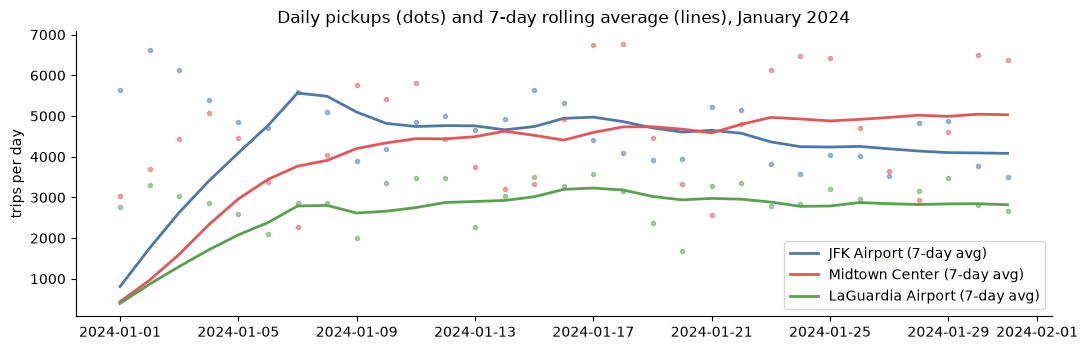

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for zid, color in [(132, "#4E79A7"), (161, "#E15759"), (138, "#59A14F")]:
    z = sp[sp.PULocationID == zid].sort_values("day")
    ax.plot(z.day, z.trips, "o", ms=3, alpha=0.5, color=color)
    ax.plot(z.day, z.avg7_calendar, "-", lw=2, color=color, label=f"{zone_name[zid]} (7-day avg)")
ax.set(title="Daily pickups (dots) and 7-day rolling average (lines), January 2024", ylabel="trips per day")
ax.legend(); plt.tight_layout(); plt.show()

*Insight: Spark and DuckDB return the same rows and the same 7-day averages (maximum difference 0.0). The chart shows why a rolling average helps: daily pickups swing with the weekday, while the 7-day line shows
the trend. The first six days of each line are low because the frame has fewer than 7 days of data before
January 7 (a warm-up period: drop it or compute it from December data).*

## Real-World Use Case or Analogy

A window function is like a teacher who grades each student's test but writes the class rank and the student's
improvement since the last test next to the grade: every row stays, and each row gets context from its group.

Companies use window functions everywhere in analytics SQL: top-N products per category, the previous order of each
customer (churn and repeat-purchase features), 7-day and 28-day rolling metrics on dashboards, deduplication
(`row_number() = 1` per key, keep the latest), and sessionization of web and app events. In Spark, the partition key
of the window is also the shuffle key, so it must have many distinct values and no single huge group.

In [9]:
daily.unpersist(); roll.unpersist()
spark.stop()